In [18]:
import pandas as pd

data = pd.read_csv("heart.csv")
df = data

In [20]:
df

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [23]:

print(df.isnull().sum())


age         0
sex         0
cp          0
trtbps      0
chol        0
fbs         0
restecg     0
thalachh    0
exng        0
oldpeak     0
slp         0
caa         0
thall       0
output      0
dtype: int64


# Exploratory Data Analysis

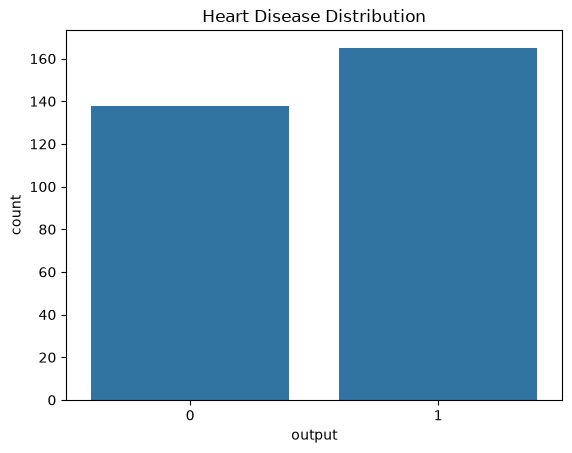

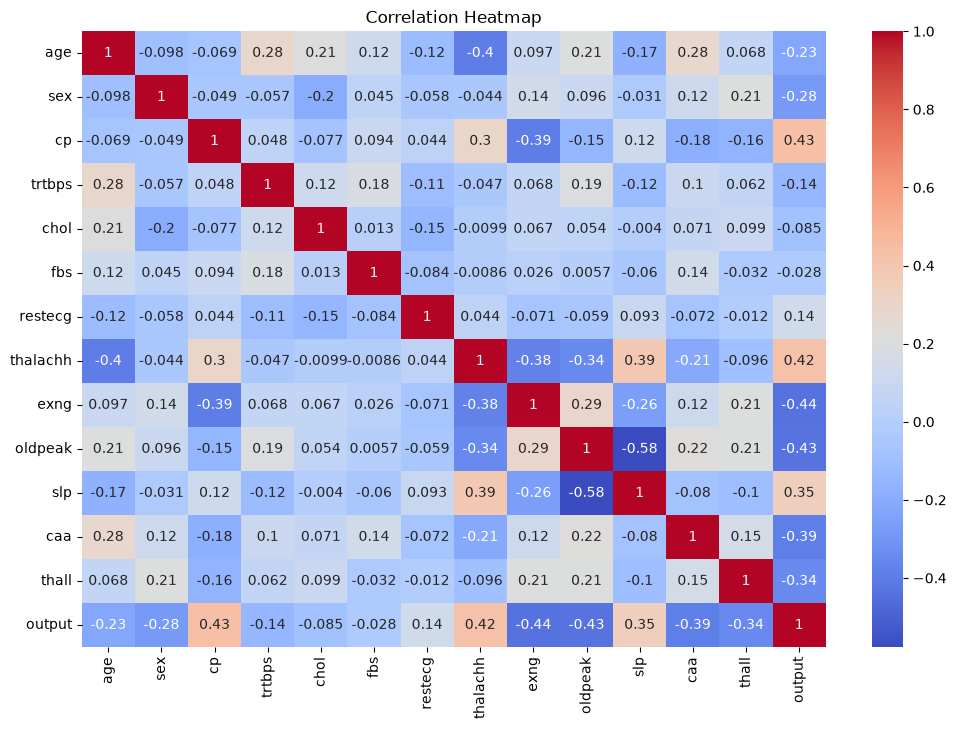

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='output', data=df)
plt.title("Heart Disease Distribution")
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

In [28]:
categorical_features = [
    'sex', 'cp', 'fbs', 'restecg',
    'exang', 'slope', 'ca', 'thal'
]

numerical_features = [
    'age', 'trestbps', 'chol',
    'thalach', 'oldpeak'
]

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

In [34]:

X = df.drop('output', axis=1)
y = df['output']

In [42]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (242, 13)
Testing data: (61, 13)


In [52]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [37]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Separate features and target
X = df.drop('output', axis=1)
y = df['output']

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Models with default parameters
models = {
    'Logistic Regression': LogisticRegression(),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'SVM': SVC()
}

results = []

# Train and evaluate
for name, model in models.items():

    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0)
    })

    print(name, "Training Completed")

# Comparison
results_df = pd.DataFrame(results)

display(results_df.sort_values(by='F1 Score', ascending=False))

Logistic Regression Training Completed
Decision Tree Training Completed
Random Forest Training Completed
SVM Training Completed


,Model,Accuracy,Precision,Recall,F1 Score
2,Random Forest,0.868852,0.852941,0.90625,0.878788
3,SVM,0.868852,0.900000,0.84375,0.870968
0,Logistic Regression,0.852459,0.870968,0.84375,0.857143
1,Decision Tree,0.852459,0.925926,0.78125,0.847458


In [77]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
            
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
            
X_test_scaled = scaler.transform(X_test)
            
knn = KNeighborsClassifier(n_neighbors=12)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)
            
print("Scaled KNN Accuracy:", accuracy_score(y_test, y_pred))        
            

Scaled KNN Accuracy: 0.8688524590163934


#12 max  0.8688524590163934

# Grid Search CV 

In [83]:
from sklearn.model_selection import GridSearchCV

In [84]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC())
])

In [86]:
param_grid = {
    'svm__C': [1, 10, 20, 30],
    'svm__kernel': ['rbf', 'linear']
}

In [88]:
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    return_train_score=False
)

In [89]:
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...svm', SVC())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'svm__C': [1, 10, ...], 'svm__kernel': ['rbf', 'linear']}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of informatio

In [ ]:
result = pd.DataFrame(grid_search.

In [90]:
print("Best Parameters:", grid_search.best_params_)

Best Parameters: {'svm__C': 1, 'svm__kernel': 'linear'}


In [92]:

results_df = pd.DataFrame(grid_search.cv_results_)

In [93]:
results_df

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_svm__C,param_svm__kernel,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.006202,0.007421,0.001573,0.000347,1,rbf,"{'svm__C': 1, 'svm__kernel': 'rbf'}",0.734694,0.795918,0.854167,0.812500,0.812500,0.801956,0.038753,5
1,0.002985,0.000455,0.001118,0.000055,1,linear,"{'svm__C': 1, 'svm__kernel': 'linear'}",0.795918,0.775510,0.854167,0.875000,0.895833,0.839286,0.046136,1
2,0.002605,0.000106,0.001254,0.000012,10,rbf,"{'svm__C': 10, 'svm__kernel': 'rbf'}",0.714286,0.755102,0.812500,0.833333,0.791667,0.781378,0.042345,6
3,0.009687,0.001740,0.001231,0.000073,10,linear,"{'svm__C': 10, 'svm__kernel': 'linear'}",0.795918,0.775510,0.854167,0.875000,0.895833,0.839286,0.046136,1
4,0.002703,0.000026,0.001260,0.000007,20,rbf,"{'svm__C': 20, 'svm__kernel': 'rbf'}",0.714286,0.755102,0.812500,0.791667,0.791667,0.773044,0.034713,8
5,0.016087,0.004120,0.001160,0.000016,20,linear,"{'svm__C': 20, 'svm__kernel': 'linear'}",0.795918,0.775510,0.854167,0.875000,0.895833,0.839286,0.046136,1
6,0.002697,0.000029,0.001246,0.000003,30,rbf,"{'svm__C': 30, 'svm__kernel': 'rbf'}",0.714286,0.775510,0.812500,0.791667,0.791667,0.777126,0.033543,7
7,0.017462,0.006419,0.001177,0.000020,30,linear,"{'svm__C': 30, 'svm__kernel': 'linear'}",0.795918,0.775510,0.854167,0.875000,0.895833,0.839286,0.046136,1


In [94]:
from sklearn.neighbors import KNeighborsClassifier


knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])


knn_param_grid = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 12, 15, 20],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan']
}


knn_grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    cv=5,
    return_train_score=False
)

knn_grid_search.fit(X_train, y_train)

print("Best KNN Parameters:", knn_grid_search.best_params_)
print("Best Cross-Validation Accuracy:", knn_grid_search.best_score_)

knn_results_df = pd.DataFrame(knn_grid_search.cv_results_)
display(knn_results_df[['params', 'mean_test_score', 'rank_test_score']].sort_values(by='rank_test_score').head(10))

Best KNN Parameters: {'knn__metric': 'manhattan', 'knn__n_neighbors': 9, 'knn__weights': 'uniform'}
Best Cross-Validation Accuracy: 0.8351190476190474


,params,mean_test_score,rank_test_score
22,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.835119,1
23,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.830952,2
29,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.830952,2
28,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.830952,2
31,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.826871,5
20,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.826871,6
30,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.826786,7
21,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.826786,8
17,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.826701,9
16,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.826701,9


In [95]:
# Evaluate your best GridSearch KNN model on the actual test set
best_knn = knn_grid_search.best_estimator_
test_preds = best_knn.predict(X_test)

print("Best KNN Test Set Accuracy:", accuracy_score(y_test, test_preds))

Best KNN Test Set Accuracy: 0.7868852459016393
